<a href="https://colab.research.google.com/github/3B232056/2026_DL_hws/blob/main/hw4_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

匯入套件

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.layers import Dropout

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 746s 4us/step


#資料預處理

*  訓練/測試資料形狀





In [3]:
print("訓練資料筆數:", len(x_train))
print("測試資料筆數:", len(x_test))

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)

print("x_test:", x_test.shape)
print("y_test:", y_test.shape)


label_dict = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

訓練資料筆數: 50000
測試資料筆數: 10000
x_train: (50000, 32, 32, 3)
y_train: (50000, 1)
x_test: (10000, 32, 32, 3)
y_test: (10000, 1)


*  訓練資料圖片

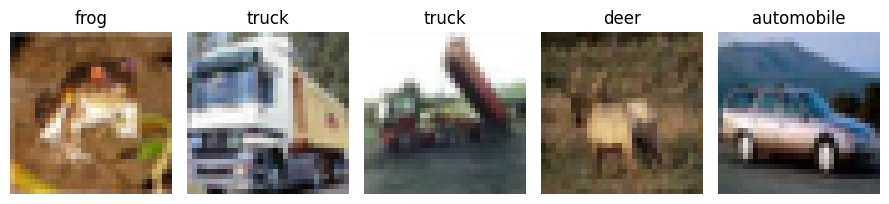

In [4]:
plt.figure(figsize=(9, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i])
    label_index = int(y_train[i][0])
    plt.title(label_dict[label_index])
    plt.axis("off")
plt.tight_layout()
plt.show()

*  拉平常模化、one-hot-encoding

In [5]:
x_train_normalize = x_train / 255
x_test_normalize = x_test / 255

y_train_OneHot = to_categorical(y_train, 10)
y_test_OneHot = to_categorical(y_test, 10)

In [6]:
print(x_train_normalize.shape)
print(x_test_normalize.shape)

print(y_train_OneHot.shape)
print(y_test_OneHot.shape)

(50000, 32, 32, 3)
(10000, 32, 32, 3)
(50000, 10)
(10000, 10)


#建立神經網路模型

In [7]:
model = Sequential()

In [8]:
#第一層：卷積層，32 個 Filter，尺寸 (5,5)
model.add(Conv2D(32, (5, 5), padding='same',
                 input_shape=(32, 32, 3),
                 activation='relu'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
# 第2層
model.add(Dropout(0.25))


In [10]:
# 第三層：池化層，尺寸 (2,2)
model.add(MaxPool2D(pool_size=(2, 2)))

In [11]:
# 第四層：卷積層，64 個 Filter，尺寸 (3,3)
model.add(Conv2D(64, (3, 3), padding='same',
                 activation='relu'))

In [12]:
# 第五層
model.add(Dropout(0.25))

In [13]:
# 第六層：池化層，尺寸 (2,2)
model.add(MaxPool2D(pool_size=(2, 2)))

In [14]:
# 第七層：拉平層
model.add(Flatten())

In [15]:
# 第八層
model.add(Dropout(0.25))

In [16]:
# 第九層：全連接層
model.add(Dense(1024, activation='relu'))

In [17]:
# 第十層
model.add(Dropout(0.25))

In [18]:
# 第十一層：全連接層
model.add(Dense(10,activation='softmax'))

In [19]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     4,195,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,226,506 (16.12 MB)

 Trainable params: 4,226,506 (16.12 MB)

 Non-trainable params: 0 (0.00 B)

#每一層參數個數


*  第一層:(5×5×3+1)×32=2432
*  第四層:(3×3×32+1) × 64=18496
*  Flatten後變成：:8×8×64 = 4096，第九層:(4096 + 1) × 1024 = 4,195,328
*  最後全連接層:(1024 + 1) × 10 = 10,250



#input shape及每一層的output shape
*  批次訓練時的input shape:(None, 32, 32, 3)
*  第一層output shape :(None, 32, 32, 32)
*  第二層output shape :(None, 32, 32, 32)
*  第三層output shape :(None, 16, 16, 32)
*  第四層output shape :(None, 16, 16, 64)
*  第五層output shape :(None, 16, 16, 64)
*  第六層output shape :(None, 8, 8, 64)
*  拉平層output shape :(None, 4096)
*  第八層output shape :(None, 4096)
*  第九層全連接層output shape :(None, 1024)   
*  第十層output shape :(None, 1024)   
*  第十一層全連接層output shape :(None, 10)

#訓練神經網路模型

In [20]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam', metrics=['accuracy'])

In [21]:
train_history = model.fit(x=x_train_normalize,
              y=y_train_OneHot,
              validation_split=0.2,
              epochs=20,
              batch_size=128,
              verbose=2)

Epoch 1/20
313/313 - 27s - 87ms/step - accuracy: 0.4242 - loss: 1.6013 - val_accuracy: 0.4568 - val_loss: 1.5635
Epoch 2/20
313/313 - 3s - 9ms/step - accuracy: 0.5566 - loss: 1.2409 - val_accuracy: 0.6137 - val_loss: 1.1869
Epoch 3/20
313/313 - 3s - 8ms/step - accuracy: 0.6217 - loss: 1.0636 - val_accuracy: 0.6428 - val_loss: 1.1002
Epoch 4/20
313/313 - 3s - 8ms/step - accuracy: 0.6660 - loss: 0.9532 - val_accuracy: 0.6469 - val_loss: 1.0318
Epoch 5/20
313/313 - 3s - 9ms/step - accuracy: 0.6935 - loss: 0.8670 - val_accuracy: 0.6815 - val_loss: 0.9572
Epoch 6/20
313/313 - 3s - 9ms/step - accuracy: 0.7294 - loss: 0.7696 - val_accuracy: 0.7034 - val_loss: 0.9079
Epoch 7/20
313/313 - 3s - 8ms/step - accuracy: 0.7580 - loss: 0.6878 - val_accuracy: 0.6909 - val_loss: 0.9135
Epoch 8/20
313/313 - 3s - 8ms/step - accuracy: 0.7864 - loss: 0.6103 - val_accuracy: 0.7107 - val_loss: 0.8464
Epoch 9/20
313/313 - 3s - 8ms/step - accuracy: 0.8130 - loss: 0.5372 - val_accuracy: 0.7111 - val_loss: 0.8423

#input shape及每一層的output shape
*  批次訓練時的input shape:(128, 32, 32, 3)
*  第一層output shape :(128, 32, 32, 16)
*  第二層output shape :(128, 32, 32, 16)
*  第三層output shape :(128, 16, 16, 16)
*  第四層output shape :(128, 16, 16, 32)
*  第五層output shape :(128, 16, 16, 32)
*  第六層output shape :(128, 8, 8, 32)
*  拉平層output shape :(128, 2048)  
*  全連接層output shape :(128, 10)   

In [22]:
def show_train_history(train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

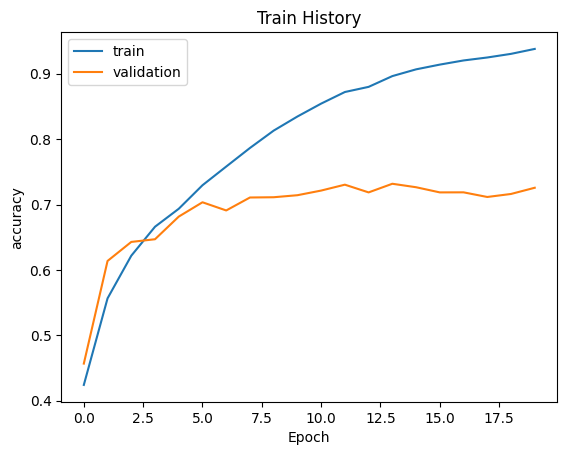

In [23]:
show_train_history(train_history,'accuracy','val_accuracy')

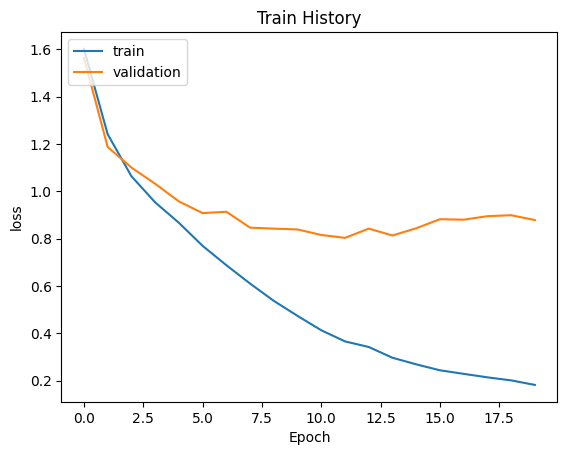

In [24]:
show_train_history(train_history,'loss','val_loss')

#結果:這兩張圖有明顯過度擬合的現象

#評估模型準確率

In [25]:
scores = model.evaluate(x_test_normalize,y_test_OneHot)

print("Loss =", scores[0])
print("正確率 =", scores[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7244 - loss: 0.8853
Loss = 0.8852661848068237
正確率 = 0.724399983882904


#hw4-1跟hw4-2比較結果
*  hw4-1

    卷積層數量較少

    沒有 Dropout

    
    訓練後容易產生 Overfitting

    參數較少

*  hw4-2

    加入 4 個 Dropout(0.25)

    全連接層增加到 1024 個神經元

    仍存在過度擬合，但因加入 Dropout 機制，過度擬合問題相較不嚴重

    訓練準確率提高(原本0.87提升至0.93)

    驗證準確率提高(原本0.70提升至0.72)
    
    參數數量增加
* 結論:整體分類效果優於 hw4-1，且Dropout對降低Overfitting有一定幫助

#進行預測

In [26]:
y_pred_prob = model.predict(x_test_normalize)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test_OneHot, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


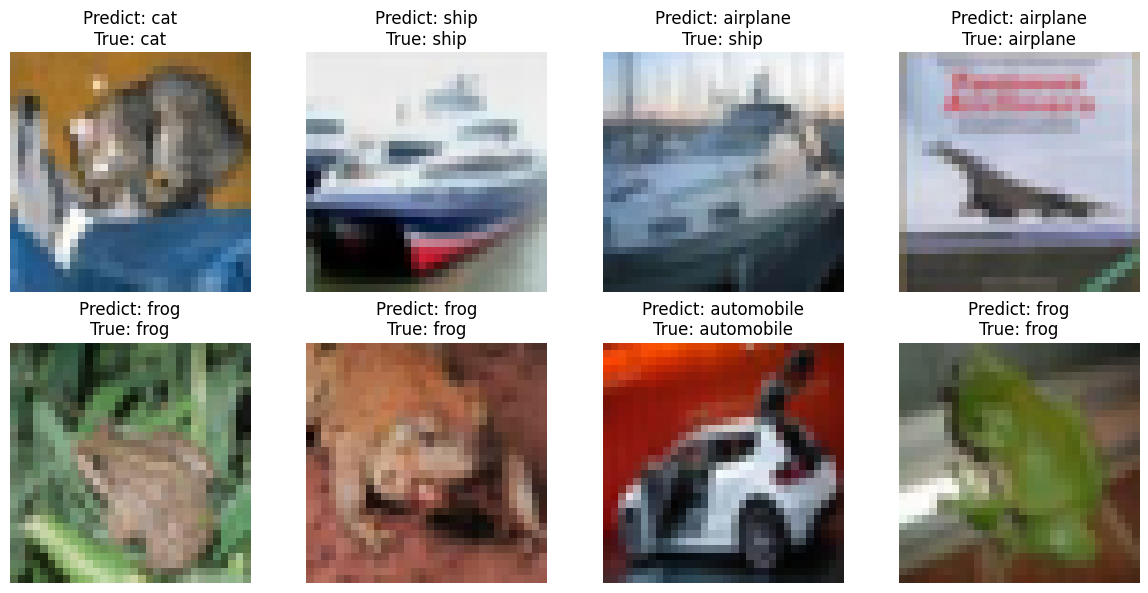

In [27]:
# 顯示 8 張測試圖片；標題為標籤名稱
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(x_test[i])
    plt.title(
        f"Predict: {label_dict[y_pred[i]]}\n"
        f"True: {label_dict[y_true[i]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

#以混淆矩陣(Confusion matrix)呈現預測結果

In [42]:
cm = pd.crosstab(y_true,y_pred,rownames=['label'],colnames=['predict'])
print(cm)

predict    0    1    2    3    4    5    6    7    8    9
label                                                    
0        789   16   29   24   15    3   13    8   80   23
1         14  842    2   12    4    5   16    5   36   64
2         76    5  565   82   94   47   77   24   22    8
3         22   10   45  575   56  126   98   33   16   19
4         27    2   53   77  660   26   94   42   14    5
5         15    5   38  217   45  564   62   40   10    4
6          4    5   18   56   16   11  877    4    6    3
7         15    2   21   51   59   57   19  756    6   14
8         42   23    8   13    7    5   10    4  873   15
9         34  100    9   25    7    9   11   17   45  743


In [43]:
# 建立 DataFrame
df = pd.DataFrame({
    'label': y_true,
    'predict': y_pred
})

# 顯示前 10 筆測試資料
df[:10]

,label,predict
0,3,3
1,8,8
2,8,0
3,0,0
4,6,6
5,6,6
6,1,1
7,6,6
8,3,3
9,1,1


In [44]:
df[(df.label==4)&(df.predict==1)]  # 真實標籤為4，卻預測為1

,label,predict
1049,4,1
4703,4,1


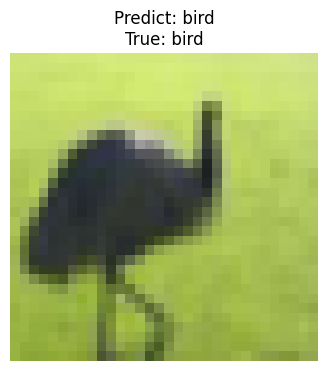

In [38]:
#預測正確
idx = 123

plt.figure(figsize=(4,4))
plt.imshow(x_test[idx])

plt.title(
    f"Predict: {label_dict[y_pred[idx]]}\n"
    f"True: {label_dict[y_true[idx]]}"
)

plt.axis("off")
plt.show()

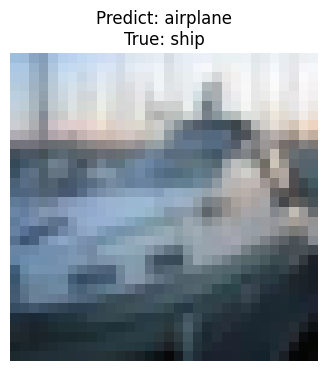

In [40]:
#預測錯誤
idx = 2

plt.figure(figsize=(4,4))
plt.imshow(x_test[idx])

plt.title(
    f"Predict: {label_dict[y_pred[idx]]}\n"
    f"True: {label_dict[y_true[idx]]}"
)

plt.axis("off")
plt.show()

#儲存完整模型

In [45]:
#儲存 model
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [46]:
%cd '/content/drive/My Drive/Colab Notebooks'

/content/drive/My Drive/Colab Notebooks


In [47]:
model.save('my_cnn_model_hw4-2.keras')

#interact_manual

In [48]:
from ipywidgets import interact_manual

In [49]:
def test(測試編號):

    plt.figure(figsize=(4,4))
    plt.imshow(x_test[測試編號])
    plt.axis('off')
    plt.show()

    pred_class = y_pred[測試編號]
    actual_class = y_true[測試編號]

    print('神經網路判斷為:',
          label_dict[pred_class],
          f'({pred_class})')

    print('實際答案為:',
          label_dict[actual_class],
          f'({actual_class})')

interact_manual(test, 測試編號=(0,9999))

interactive(children=(IntSlider(value=4999, description='測試編號', max=9999), Button(description='Run Interact', …

<function __main__.test(測試編號)>